## 3D Fiber Segmentation

### Objective:
Segment fibers in a 3D image from MicroCT scans using different methods of continuity such as the one used in 2D and based on Persistence Length.

In [1]:
# Librarys and functions

import os
import numpy as np
import pandas as pd
import tifffile
import matplotlib.pyplot as plt
import plotly.graph_objects as go
from PIL import Image
from skimage.measure import label
from scipy.spatial import cKDTree
from skimage.morphology import remove_small_objects
from skimage.color import label2rgb, gray2rgb
from skimage.measure import label, regionprops
from skimage.morphology import skeletonize
from skimage.util import invert, img_as_float
from skan import Skeleton, summarize
from itertools import combinations
from scipy.ndimage import distance_transform_edt
from skimage.segmentation import watershed
from skimage.io import imread
from skimage import filters, restoration
from tqdm import tqdm
from IPython.display import clear_output

In [2]:


def skeletonize_3D():
    return skeleton_obj

In [3]:
# Importing imagem
# Image options:
#   "./fiber_img/PPGF40.tif"
#   "./fiber_img/PPGF40HNT0-1.0.tif"
#   "./fiber_img/PPGF40HNT0-1.5.tif"
#   "./fiber_img/PPGF40HNT0-5.tif"

filename = "./fiber_img/PPGF40HNT0-1.0.tif"
raw_tiff_img = tifffile.imread(filename)

# Converting to 8bits gray scale
raw_tiff_img = (raw_tiff_img / np.max(raw_tiff_img) * 255).astype(np.uint8)

Selected image:  ./fiber_img/PPGF40HNT0-1.0.tif
Dimensions raw image:  
 X:  1649  
 Y:  1055  
 Z:  658
Dimensions selected image (no shadows):   
 X:  1649  
 Y:  815  
 Z:  405


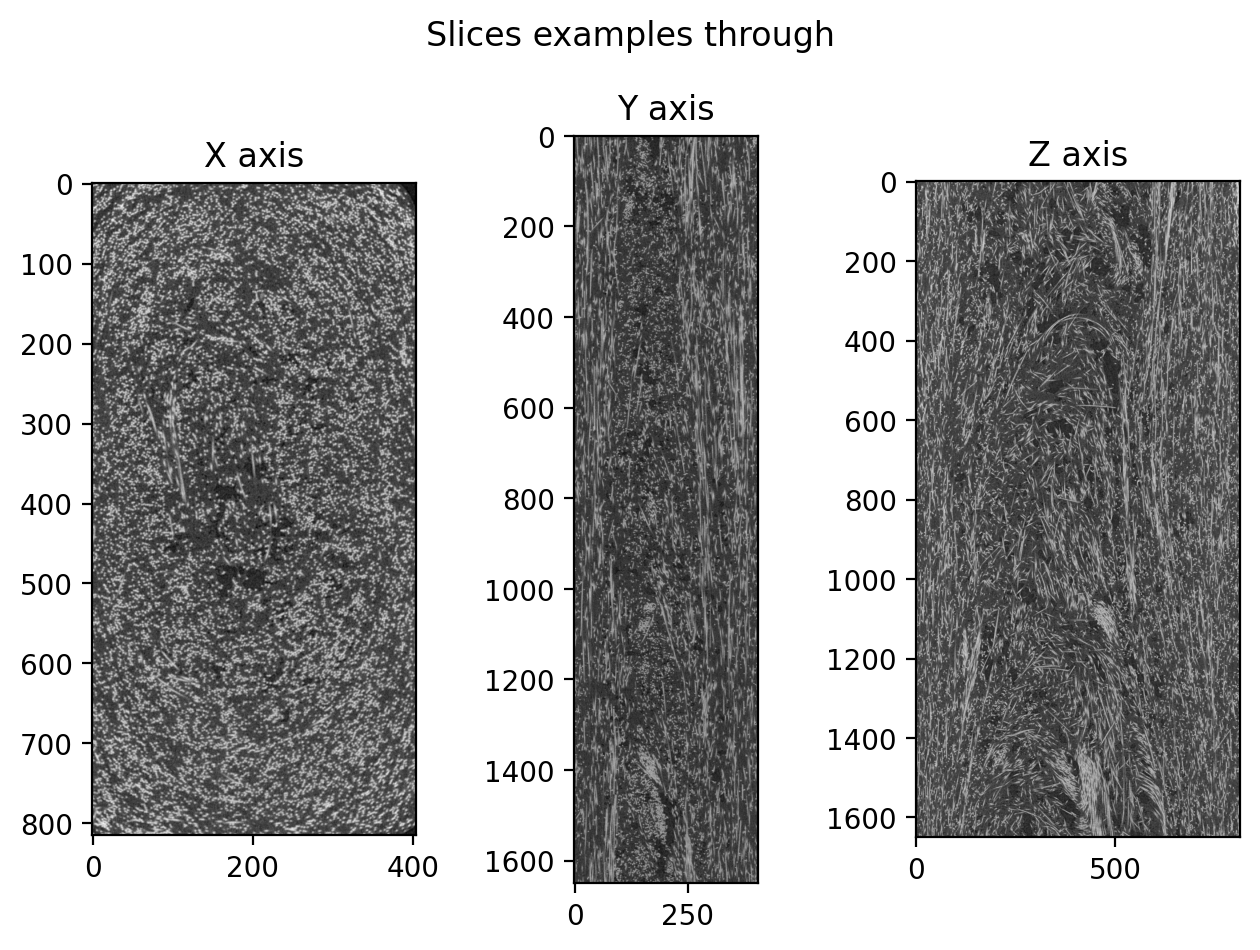

In [4]:
# Details of the image
print("Selected image: ", filename)
print("Dimensions raw image:",
      " \n X: ", raw_tiff_img.shape[0], 
      " \n Y: ", raw_tiff_img.shape[1], 
      " \n Z: ", raw_tiff_img.shape[2])

# Selecting only the slices with no shadows
if filename == "./fiber_img/PPGF40HNT0-1.0.tif":
    selected_tiff_img = raw_tiff_img[:, 125:940, 130:535]

print("Dimensions selected image (no shadows): ",
      " \n X: ", selected_tiff_img.shape[0], 
      " \n Y: ", selected_tiff_img.shape[1], 
      " \n Z: ", selected_tiff_img.shape[2])

# Axis plot
plt.figure(dpi=200)
plt.suptitle("Slices examples through")
plt.subplot(1,3,1)
plt.imshow(selected_tiff_img[500,:,:], cmap='gray')
plt.title("X axis")

plt.subplot(1,3,2)
plt.imshow(selected_tiff_img[:,400,:], cmap='gray')
plt.title("Y axis")

plt.subplot(1,3,3)
plt.imshow(selected_tiff_img[:,:,200], cmap='gray')
plt.title("Z axis")

plt.tight_layout()
plt.show()

In [5]:
# Selecting a 3D cubic section of the block for tests
n_pixels = 50

mean_X = round(selected_tiff_img.shape[0]/2)
mean_Y = round(selected_tiff_img.shape[1]/2)
mean_Z = round(selected_tiff_img.shape[2]/2)

n_pixels_each_side = round(n_pixels/2)

cropped_img = selected_tiff_img[mean_X-n_pixels_each_side:mean_X+n_pixels_each_side,
                                mean_Y-n_pixels_each_side:mean_Y+n_pixels_each_side,
                                mean_Z-n_pixels_each_side:mean_Z+n_pixels_each_side]